In [20]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import zipfile
from pathlib import Path

zip_path = Path("/content/drive/MyDrive/archive (3).zip")
extract_path = Path("/content/dataset")

print("ZIP exists:", zip_path.exists())
print("Valid ZIP:", zipfile.is_zipfile(zip_path))

if zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Dataset extracted successfully!")
else:
    print("Check ZIP file path or upload integrity.")

ZIP exists: True
Valid ZIP: True
Dataset extracted successfully!


In [22]:
DATA_DIR = Path("/content/dataset/dataset")

train_dir = DATA_DIR / "training_set"
test_dir = DATA_DIR / "test_set"

print("Training cats:", len(list((train_dir / "cats").glob("*.jpg"))))
print("Training dogs:", len(list((train_dir / "dogs").glob("*.jpg"))))

Training cats: 4000
Training dogs: 4000


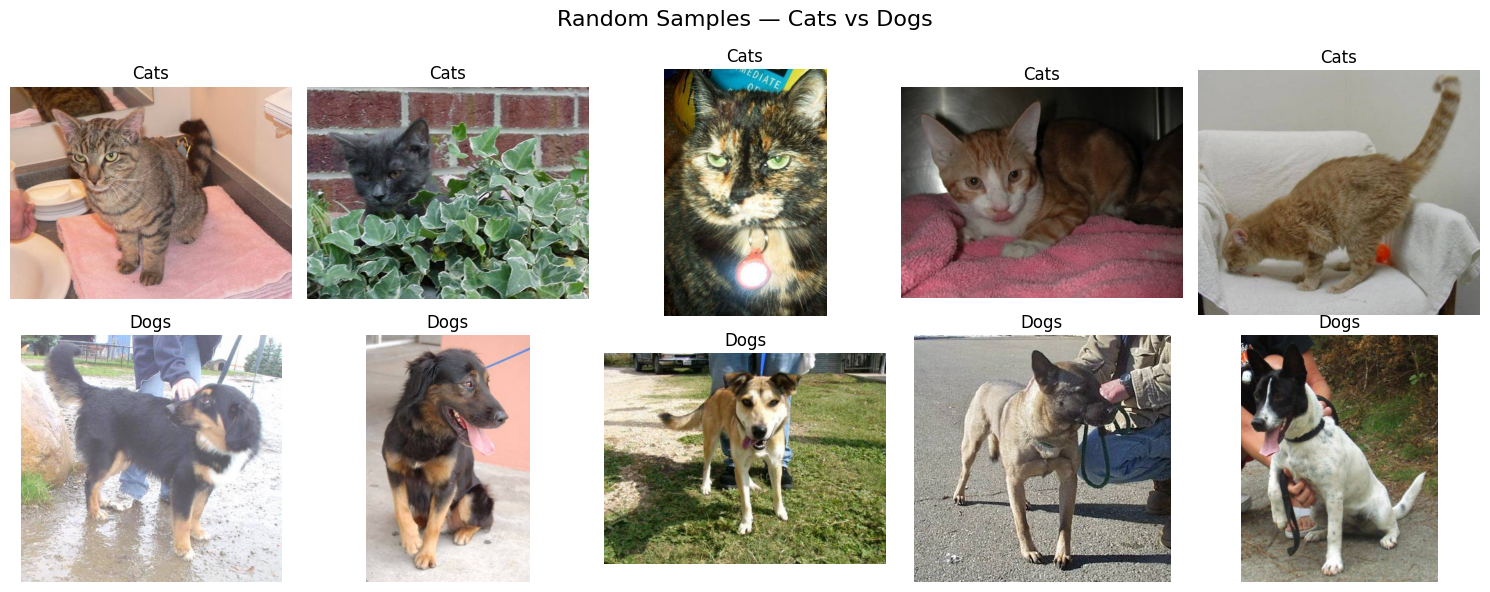

In [23]:
import matplotlib.pyplot as plt
from PIL import Image
import random

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row, label in enumerate(["cats", "dogs"]):
    image_paths = list((train_dir / label).glob("*.jpg"))
    selected = random.sample(image_paths, 5)

    for col, image_path in enumerate(selected):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(label.capitalize())
        axes[row, col].axis("off")

plt.suptitle("Random Samples — Cats vs Dogs", fontsize=16)
plt.tight_layout()
plt.show()

In [24]:
from PIL import Image
import pandas as pd

image_info = []

for label in ["cats", "dogs"]:
    for image_path in (train_dir / label).glob("*.jpg"):
        with Image.open(image_path) as img:
            width, height = img.size

        image_info.append({
            "filename": image_path.name,
            "class": label,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "resolution": width * height
        })

image_df = pd.DataFrame(image_info)

print("Dataset shape:", image_df.shape)
display(image_df.head())

Dataset shape: (8000, 6)


,filename,class,width,height,aspect_ratio,resolution
0,cat.3277.jpg,cats,239,240,0.995833,57360
1,cat.3836.jpg,cats,499,340,1.467647,169660
2,cat.3713.jpg,cats,499,352,1.417614,175648
3,cat.2017.jpg,cats,300,299,1.003344,89700
4,cat.2493.jpg,cats,437,500,0.874000,218500


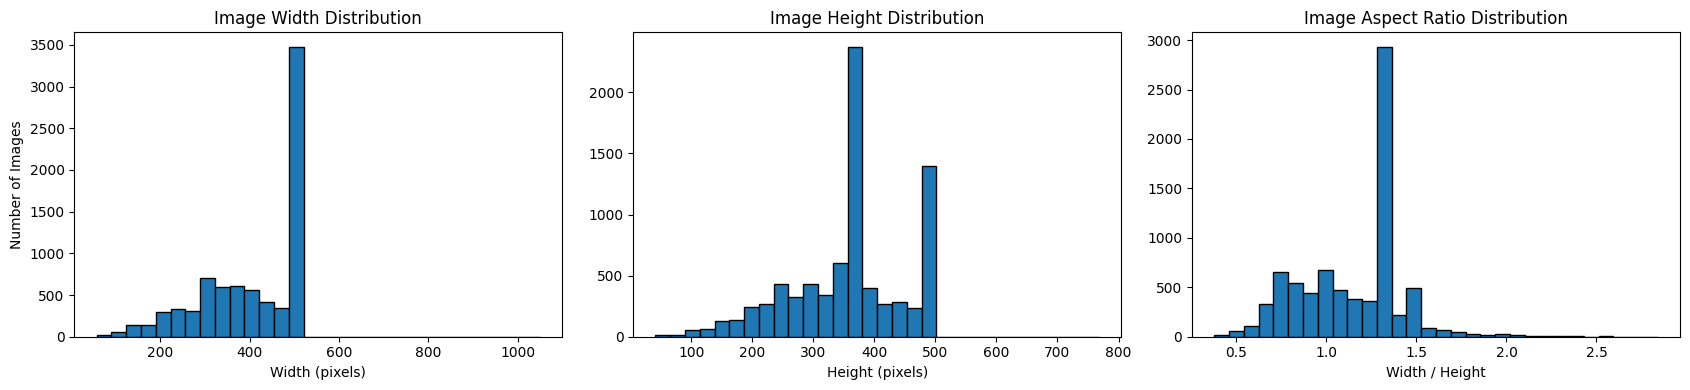

,width,height,aspect_ratio,resolution
count,8000.00,8000.00,8000.00,8000.00
mean,403.78,360.47,1.16,151082.14
std,108.83,96.94,0.29,59931.71
min,57.00,41.00,0.38,2419.00
25%,321.00,300.00,0.93,103946.00
50%,445.00,374.00,1.27,175000.00
75%,499.00,421.00,1.34,187125.00
max,1050.00,768.00,2.84,785664.00


In [25]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# Width distribution
axes[0].hist(image_df["width"], bins=30, edgecolor="black")
axes[0].set_title("Image Width Distribution")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Number of Images")

# Height distribution
axes[1].hist(image_df["height"], bins=30, edgecolor="black")
axes[1].set_title("Image Height Distribution")
axes[1].set_xlabel("Height (pixels)")

# Aspect ratio distribution
axes[2].hist(image_df["aspect_ratio"], bins=30, edgecolor="black")
axes[2].set_title("Image Aspect Ratio Distribution")
axes[2].set_xlabel("Width / Height")

plt.tight_layout()
plt.show()

display(
    image_df[["width", "height", "aspect_ratio", "resolution"]]
    .describe()
    .round(2)
)

In [26]:
# Identify potentially unusual images
unusual_images = image_df[
    (image_df["width"] < 100) |
    (image_df["height"] < 100) |
    (image_df["aspect_ratio"] < 0.5) |
    (image_df["aspect_ratio"] > 2.0)
].copy()

print("Number of unusual images:", len(unusual_images))

display(
    unusual_images.sort_values("resolution")
    .head(15)
)

Number of unusual images: 132


,filename,class,width,height,aspect_ratio,resolution
3614,cat.2433.jpg,cats,59,41,1.439024,2419
7624,dog.1324.jpg,dogs,59,45,1.311111,2655
7595,dog.2965.jpg,dogs,57,50,1.140000,2850
7592,dog.2652.jpg,dogs,61,49,1.244898,2989
6717,dog.2188.jpg,dogs,59,55,1.072727,3245
7994,dog.3147.jpg,dogs,68,50,1.360000,3400
6261,dog.1381.jpg,dogs,69,52,1.326923,3588
6550,dog.630.jpg,dogs,73,50,1.460000,3650
5964,dog.1174.jpg,dogs,74,50,1.480000,3700
5066,dog.2068.jpg,dogs,59,70,0.842857,4130


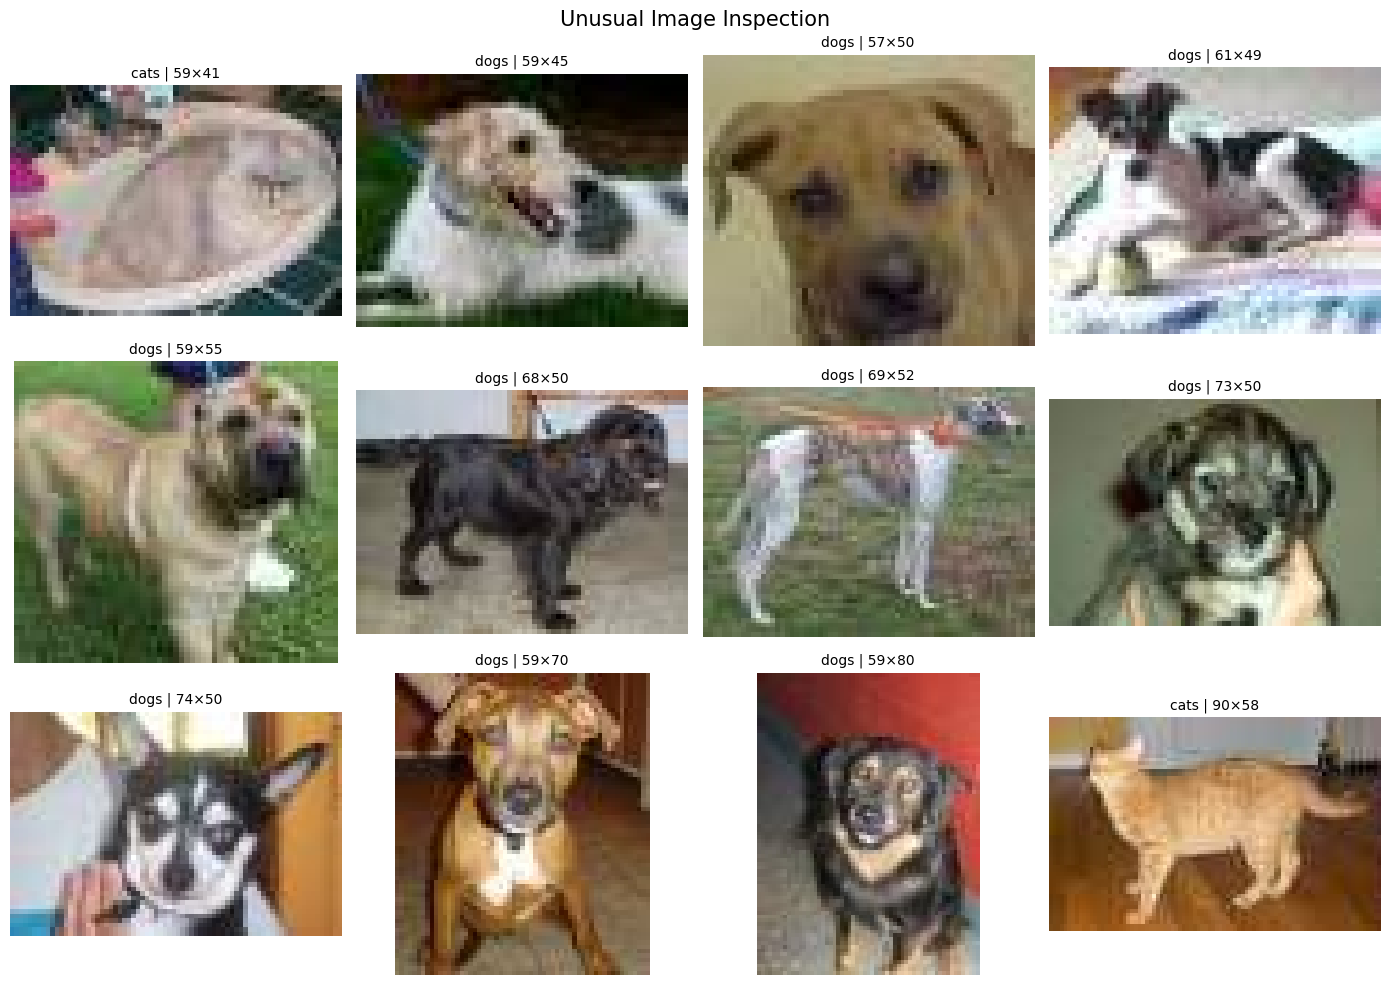

In [27]:
import matplotlib.pyplot as plt
from PIL import Image

# Display up to 12 unusual images
samples = unusual_images.sort_values("resolution").head(12)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    image_path = train_dir / row["class"] / row["filename"]

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(
        f'{row["class"]} | {row["width"]}×{row["height"]}',
        fontsize=10
    )
    ax.axis("off")

for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.suptitle("Unusual Image Inspection", fontsize=15)
plt.tight_layout()
plt.show()

In [28]:
from PIL import Image, UnidentifiedImageError
from collections import defaultdict
import hashlib
import pandas as pd

records = []
corrupted = []

for split, root in [("train", train_dir), ("test", test_dir)]:
    for label in ["cats", "dogs"]:
        for path in sorted((root / label).glob("*.jpg")):
            try:
                with Image.open(path) as img:
                    img.load()
                    rgb = img.convert("RGB")

                    # Hash decoded pixels and dimensions
                    digest = hashlib.sha256(
                        str(rgb.size).encode() + rgb.tobytes()
                    ).hexdigest()

                records.append({
                    "split": split,
                    "class": label,
                    "path": str(path),
                    "hash": digest
                })

            except Exception as e:
                corrupted.append({
                    "path": str(path),
                    "error": str(e)
                })

quality_df = pd.DataFrame(records)

duplicates = quality_df[
    quality_df.duplicated("hash", keep=False)
].sort_values("hash")

print("Successfully decoded:", len(quality_df))
print("Corrupted images:", len(corrupted))
print("Images in duplicate groups:", len(duplicates))
print("Unique duplicate groups:", duplicates["hash"].nunique())

# Check duplicate content appearing across train and test
cross_split = quality_df.groupby("hash")["split"].nunique()
print("Duplicate groups across train/test:",
      (cross_split > 1).sum())

Successfully decoded: 10000
Corrupted images: 0
Images in duplicate groups: 2
Unique duplicate groups: 1
Duplicate groups across train/test: 0


,split,class,path,hash
5143,train,dogs,/content/dataset/dataset/training_set/dogs/dog...,ea29363449c84b2661294cd817e8259e7ed5e14f87bec9...
6315,train,dogs,/content/dataset/dataset/training_set/dogs/dog...,ea29363449c84b2661294cd817e8259e7ed5e14f87bec9...


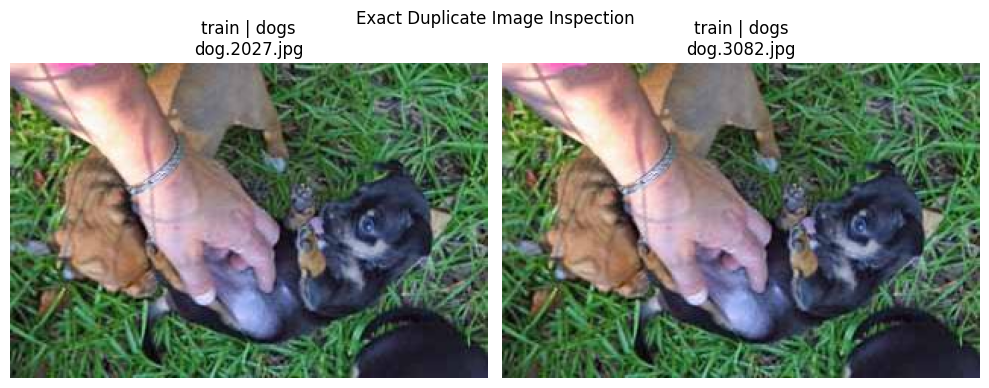

In [29]:
# Display duplicate image information
display(
    duplicates[["split", "class", "path", "hash"]]
)

# Visualize duplicate images
fig, axes = plt.subplots(1, len(duplicates), figsize=(10, 4))

for ax, (_, row) in zip(axes, duplicates.iterrows()):
    with Image.open(row["path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(
        f'{row["split"]} | {row["class"]}\n'
        f'{Path(row["path"]).name}'
    )
    ax.axis("off")

plt.suptitle("Exact Duplicate Image Inspection")
plt.tight_layout()
plt.show()

In [30]:
# Keep one image per unique pixel hash in training
train_clean_df = (
    quality_df[quality_df["split"] == "train"]
    .drop_duplicates(subset="hash", keep="first")
    .copy()
)

test_clean_df = quality_df[
    quality_df["split"] == "test"
].copy()

print("Original training images:", 8000)
print("Cleaned training images:", len(train_clean_df))
print("Test images:", len(test_clean_df))

print("\nCleaned training class distribution:")
print(train_clean_df["class"].value_counts())

Original training images: 8000
Cleaned training images: 7999
Test images: 2000

Cleaned training class distribution:
class
cats    4000
dogs    3999
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

SEED = 42

train_df, val_df = train_test_split(
    train_clean_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_clean_df["class"]
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_clean_df))

print("\nTraining class distribution:")
print(train_df["class"].value_counts())

print("\nValidation class distribution:")
print(val_df["class"].value_counts())

# Verify no image paths are shared
assert set(train_df["path"]).isdisjoint(set(val_df["path"]))

print("\nTrain/validation path overlap: 0")

Training images: 6399
Validation images: 1600
Testing images: 2000

Training class distribution:
class
cats    3200
dogs    3199
Name: count, dtype: int64

Validation class distribution:
class
dogs    800
cats    800
Name: count, dtype: int64

Train/validation path overlap: 0


In [32]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

def load_image(path, label):
    # Read image file
    image = tf.io.read_file(path)

    # Decode JPG as RGB
    image = tf.image.decode_jpeg(image, channels=3)

    # Resize while preserving aspect ratio using padding
    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE[0],
        IMG_SIZE[1]
    )

    # Convert pixel values from [0, 255] to [0, 1]
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_dataset(df, training=False):
    paths = df["path"].astype(str).values

    # Cats = 0, Dogs = 1
    labels = (df["class"] == "dogs").astype("float32").values

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_clean_df)

# Inspect a single batch
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))
    print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 160, 160, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0
First 10 labels: [1. 1. 0. 0. 0. 0. 0. 0. 0. 0.]


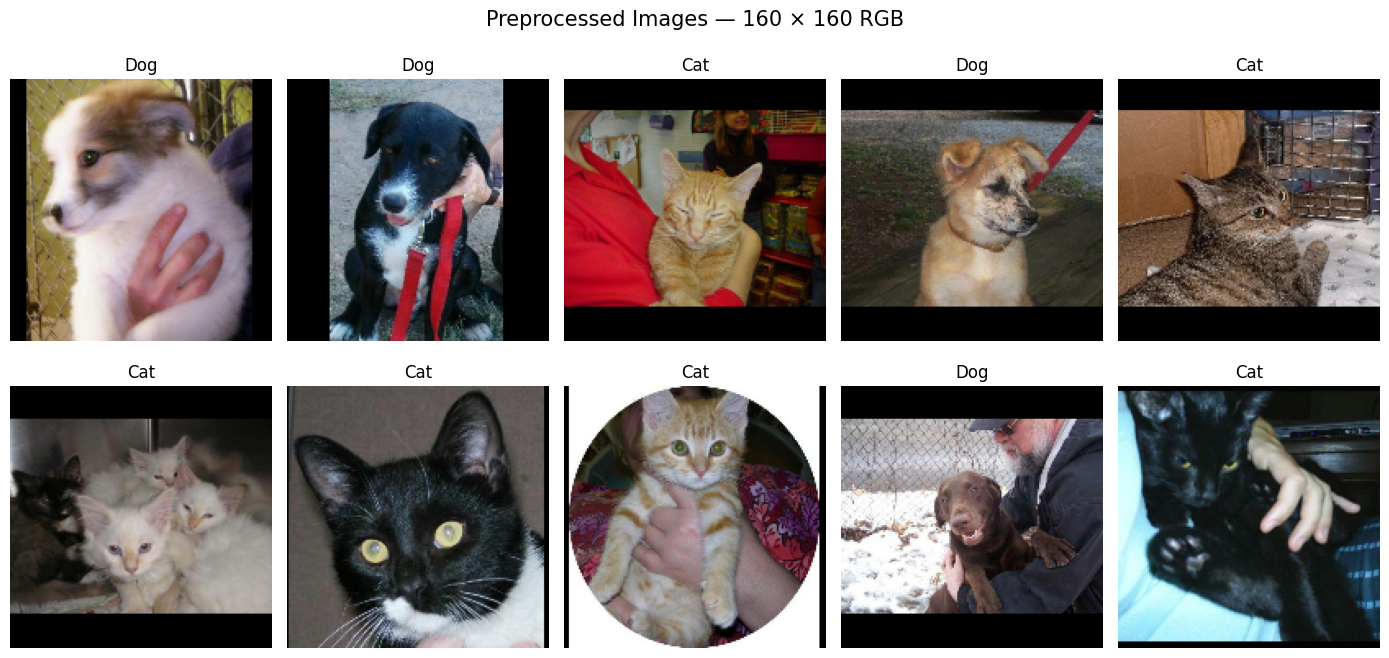

In [33]:
import matplotlib.pyplot as plt

# Take one batch from the training dataset
images, labels = next(iter(train_ds))

fig, axes = plt.subplots(2, 5, figsize=(14, 7))

class_names = ["Cat", "Dog"]

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].numpy())

    label = int(labels[i].numpy())

    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle(
    "Preprocessed Images — 160 × 160 RGB",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [34]:
from tensorflow.keras import layers
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10)
], name="data_augmentation")

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


In [35]:
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),

    data_augmentation,

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,561 (431.88 KB)

 Trainable params: 110,113 (430.13 KB)

 Non-trainable params: 448 (1.75 KB)

In [36]:
import tensorflow as tf

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [42]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath="/content/best_cats_dogs_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks = [
    early_stopping,
    reduce_lr,
    checkpoint
]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


In [43]:
history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6793 - loss: 0.5994 - precision: 0.6928 - recall: 0.6490
Epoch 1: val_loss improved from None to 0.61615, saving model to /content/best_cats_dogs_cnn.keras

Epoch 1: finished saving model to /content/best_cats_dogs_cnn.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 16s 78ms/step - accuracy: 0.6765 - loss: 0.6031 - precision: 0.6954 - recall: 0.6280 - val_accuracy: 0.6519 - val_loss: 0.6161 - val_precision: 0.6758 - val_recall: 0.5838 - learning_rate: 5.0000e-04
Epoch 2/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6781 - loss: 0.5915 - precision: 0.6858 - recall: 0.6288
Epoch 2: val_loss improved from 0.61615 to 0.57310, saving model to /content/best_cats_dogs_cnn.keras

Epoch 2: finished saving model to /content/best_cats_dogs_cnn.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 20s 78ms/step - accuracy: 0.6862 - loss: 0.5898 - precision: 0.7033 - recall: 0.6440 - val_accuracy: 0.7063 - val_loss: 0.5731 - val_precision: 0.6993 - va

In [44]:
import tensorflow as tf

# Load the best saved model
best_model = tf.keras.models.load_model(
    "/content/best_cats_dogs_cnn.keras"
)

# Evaluate on unseen test images
test_results = best_model.evaluate(
    test_ds,
    return_dict=True,
    verbose=1
)

print("\nFinal Test Performance")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.7480 - loss: 0.5279 - precision: 0.7500 - recall: 0.7440

Final Test Performance
accuracy: 0.7480
loss: 0.5279
precision: 0.7500
recall: 0.7440
